## 1. n fitting of unperturbed and occluded data


In [51]:
import os
import pickle
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import pandas as pd
import optax
from jaxopt import AndersonAcceleration

m = 2 #mitral count
x = jnp.ones(m) #OSN input

In [52]:
# Naka-Rushton function
# to avoid numerical issues - make sure x is non-negative

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

Fixing Hill exponents from Elisa

Fit n and scale per cell class from Elisa's firing rate curves `n_r, n_b, n_g, n_y` 
(firing rates vs injected current)

In [53]:
def nr_full(x, n, b, y_max):
    return nr(x / b, n) * y_max

# Mitral cells

In [54]:
df_mitral_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,G:AB',
    nrows=45
)
#df_mitral_unperturbed

In [55]:
df_mitral_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,AG:BE',
    nrows=45
)
#df_mitral_occluded

# Red cells (ETCs)

In [56]:
df_red_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=4,
    usecols='J,N:AQ',
    nrows=35
).dropna(how='all').astype(float)
#df_red_unperturbed

In [57]:
df_red_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=41,
    usecols='J,N:AQ',
    nrows=73
).dropna(how='all').astype(float)

# Green cells

In [58]:
df_green_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,C:L',
    nrows=51
).dropna(how='all').astype(float)
#df_green_unperturbed

In [59]:
df_green_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,Y:AH',
    nrows=51
).dropna(how='all').astype(float)
#df_green_occluded

# Blue cells

In [60]:
df_blue_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,N:V',
    nrows=51
).dropna(how='all').astype(float)
#df_blue_unperturbed

In [61]:
df_blue_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,AJ:AP',
    nrows=51
).dropna(how='all').astype(float)
#df_blue_occluded

# Plot

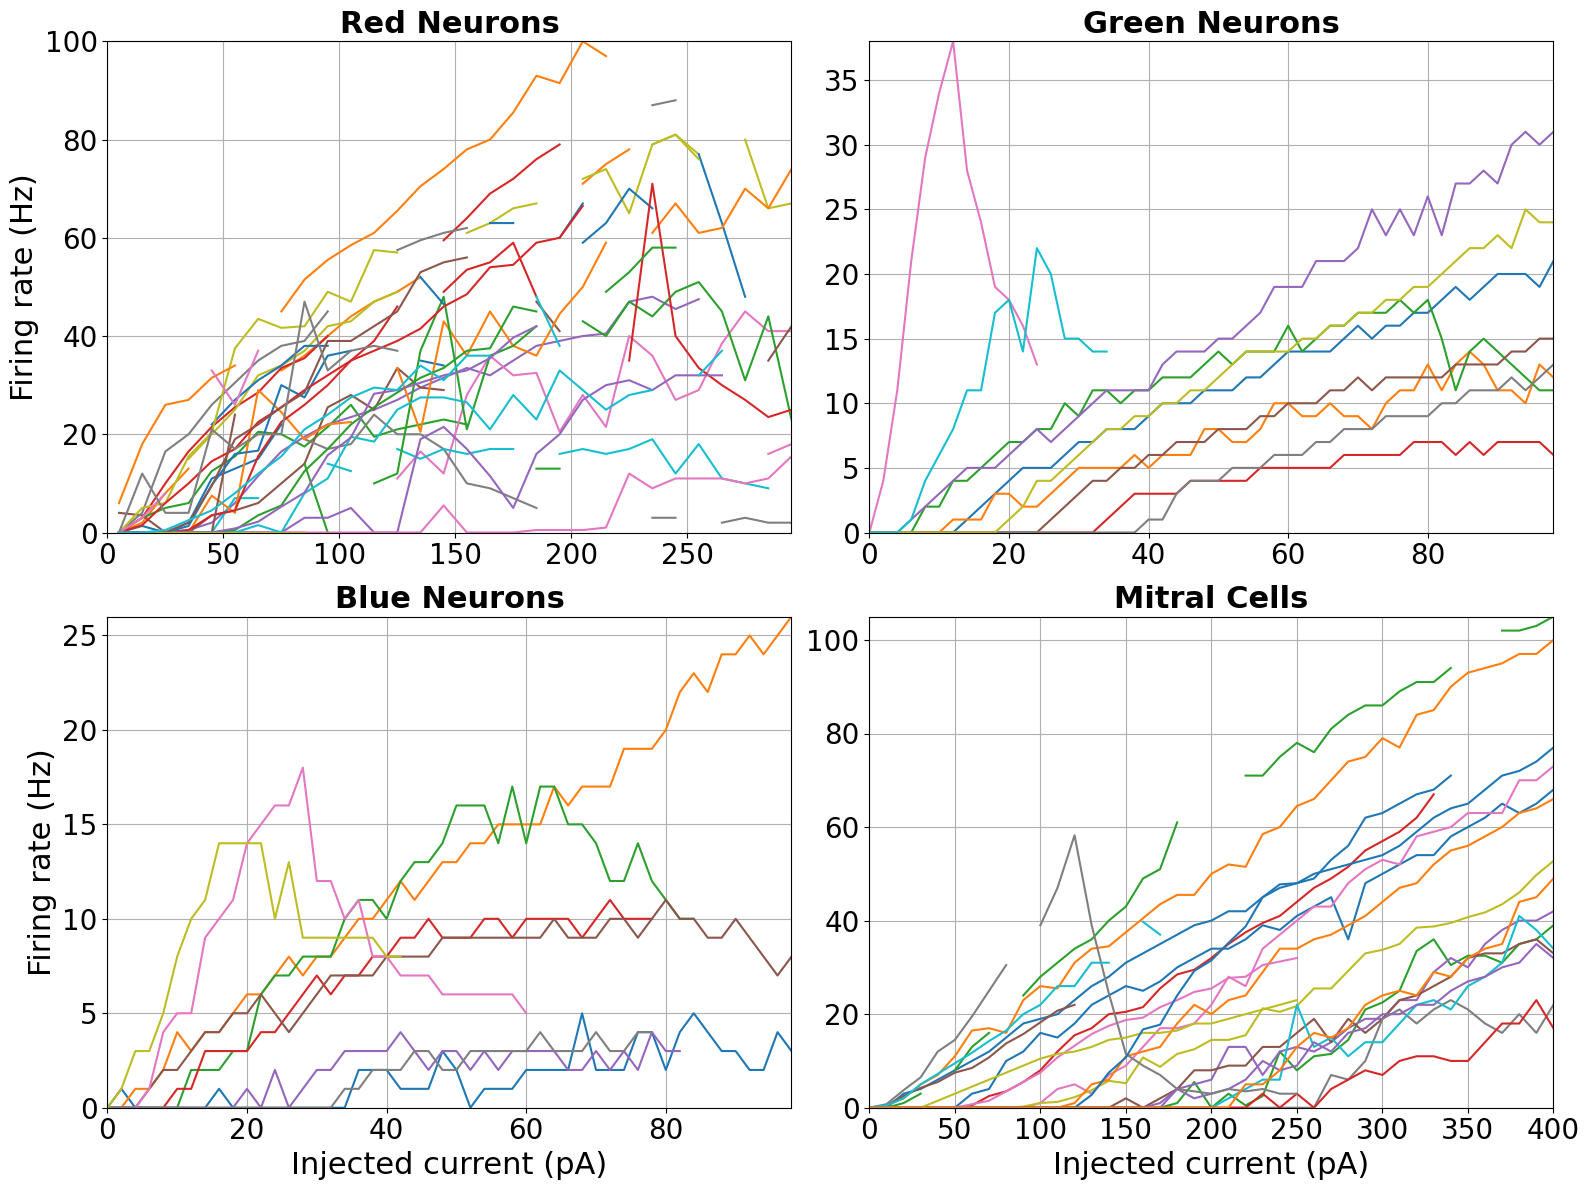

In [62]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

datasets = [
    (df_red_unperturbed, axes[0, 0], 'Red Neurons'),
    (df_green_unperturbed, axes[0, 1], 'Green Neurons'),
    (df_blue_unperturbed, axes[1, 0], 'Blue Neurons'),
    (df_mitral_unperturbed, axes[1, 1], 'Mitral Cells')
]

for df, ax, title in datasets:
    df.plot(ax=ax, legend=False)
    ax.set_title(title, fontsize=22, fontweight='bold')
    ax.set_xlim(0, df.index.max())
    ax.set_ylim(0, df.max().max())
    ax.tick_params(axis='both', labelsize=20)
    
axes[0, 0].set_xlabel('')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')

axes[0, 0].set_ylabel('Firing rate (Hz)', fontsize=22)
axes[1, 0].set_ylabel('Firing rate (Hz)', fontsize=22)

axes[1, 0].set_xlabel('Injected current (pA)', fontsize=22)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=22)
axes[0, 0].grid(True)
axes[0, 1].grid(True)
axes[1, 0].grid(True)
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(f'Figures_z/all_cells_unperturbed.eps')
plt.show()

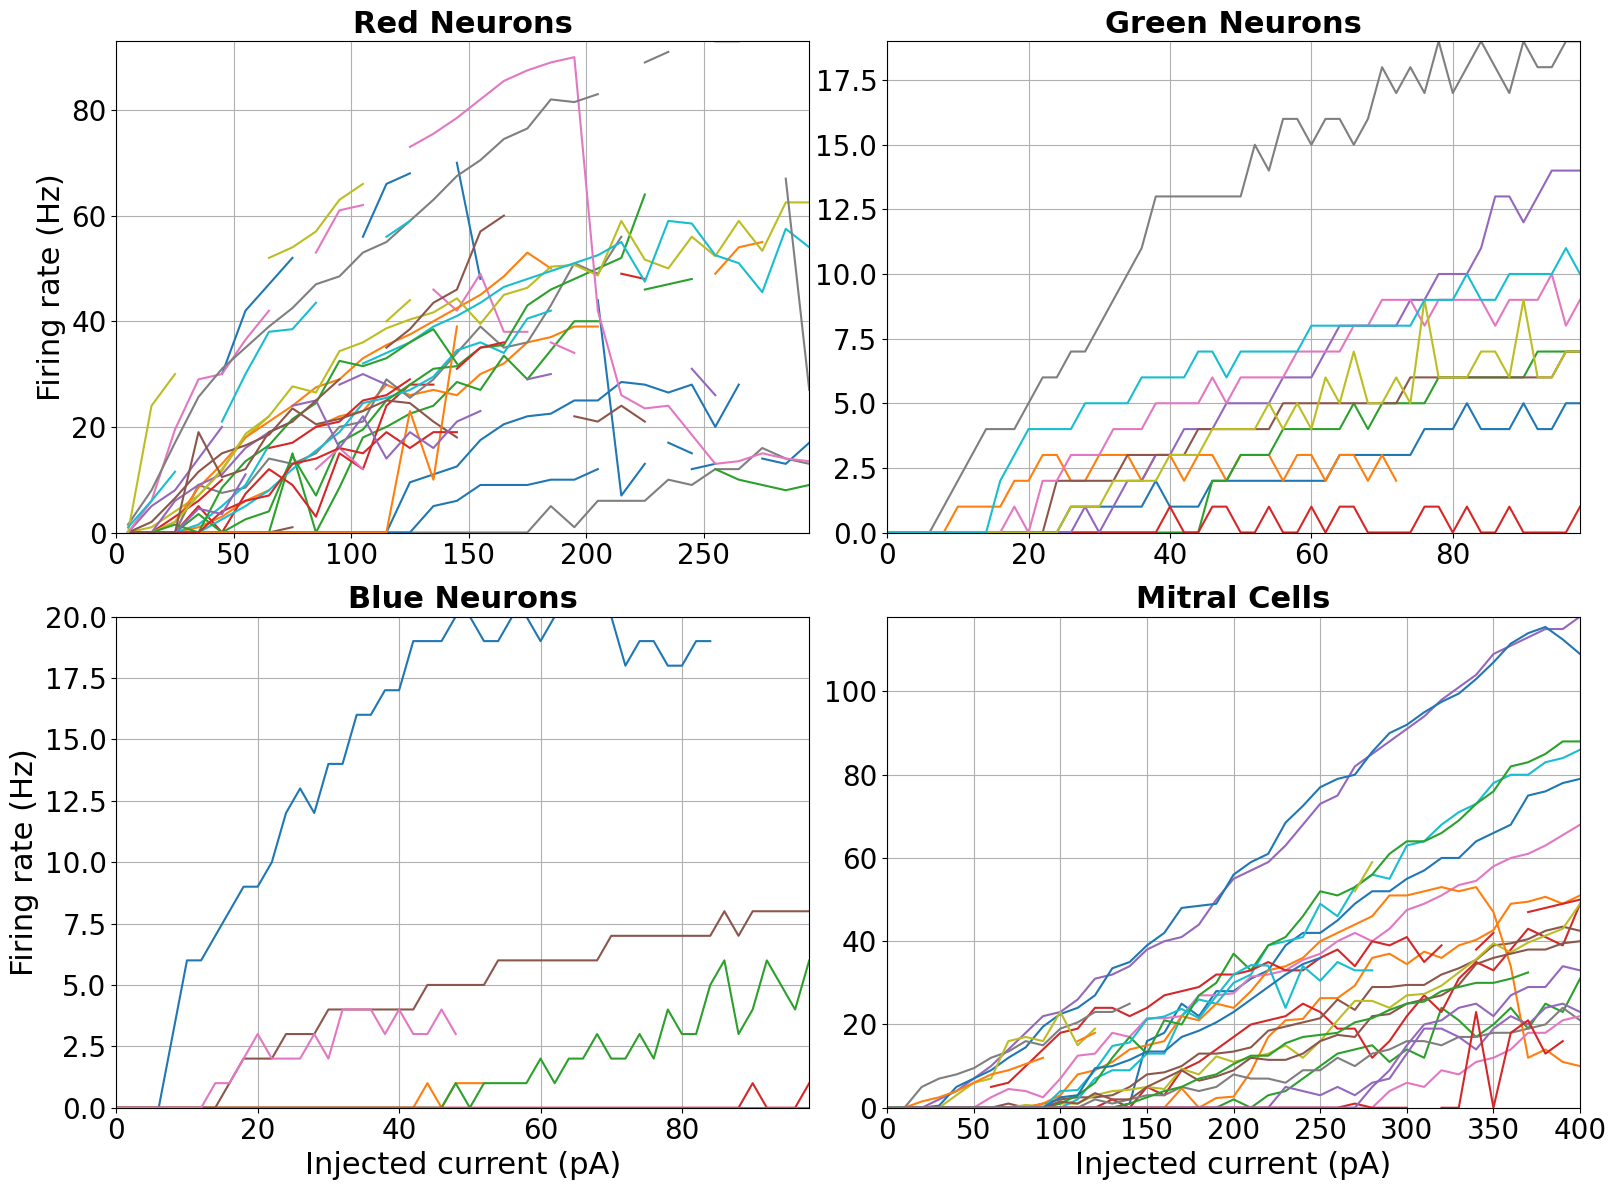

In [63]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

datasets = [
    (df_red_occluded, axes[0, 0], 'Red Neurons'),
    (df_green_occluded, axes[0, 1], 'Green Neurons'),
    (df_blue_occluded, axes[1, 0], 'Blue Neurons'),
    (df_mitral_occluded, axes[1, 1], 'Mitral Cells')
]

for df, ax, title in datasets:
    df.plot(ax=ax, legend=False)
    ax.set_title(title, fontsize=22, fontweight='bold')
    ax.set_xlim(0, df.index.max())
    ax.set_ylim(0, df.max().max())
    ax.tick_params(axis='both', labelsize=20)
    
axes[0, 0].set_xlabel('')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')

axes[0, 0].set_ylabel('Firing rate (Hz)', fontsize=22)
axes[1, 0].set_ylabel('Firing rate (Hz)', fontsize=22)

axes[1, 0].set_xlabel('Injected current (pA)', fontsize=22)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=22)
axes[0, 0].grid(True)
axes[0, 1].grid(True)
axes[1, 0].grid(True)
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(f'Figures_z/all_cells_occluded.eps')
plt.show()

## Summary


Red Neurons
n = 1.850, b = 106.970, y_max = 57.279

Green Neurons
n = 1.867, b = 63.868, y_max = 24.260

Blue Neurons
n = 0.648, b = 63523.472, y_max = 782.135

Mitral Cells
n = 1.560, b = 1407.419, y_max = 445.758


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


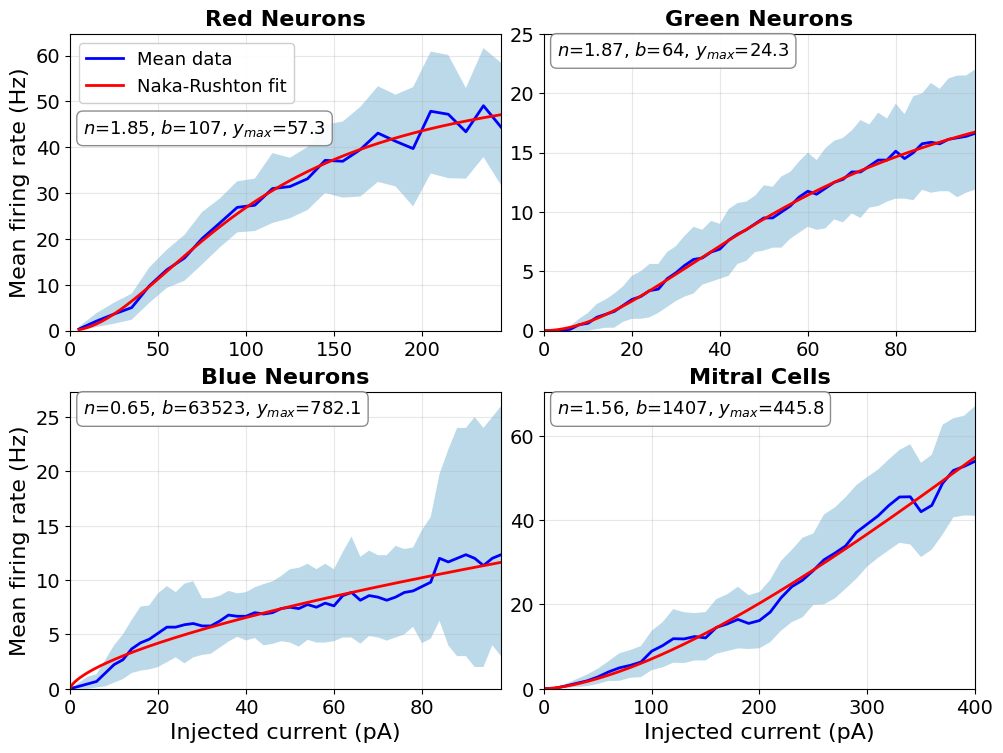

In [64]:
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG, FS_PARAM = 16, 16, 14, 13, 13
param_bbox = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.9)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), sharex=False)
dfs = [
    df_red_unperturbed.iloc[:-5],
    df_green_unperturbed.drop(columns=['B.4', 'D.1']),
    df_blue_unperturbed,
    df_mitral_unperturbed,
]
titles = ['Red Neurons', 'Green Neurons', 'Blue Neurons', 'Mitral Cells']

for i, (df_plot, title) in enumerate(zip(dfs, titles)):
    ax = axes.flat[i]
    x = np.asarray(df_plot.index, dtype=float)
    y = np.asarray(df_plot.mean(axis=1), dtype=float)
    fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100], maxfev=8000)

    print(f"\n{title}")
    print(f"n = {fit_params[0]:.3f}, b = {fit_params[1]:.3f}, y_max = {fit_params[2]:.3f}")

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = nr_full(x_fit, *fit_params)

    df_long = (
        df_plot.reset_index(names='current')
        .melt(id_vars='current', var_name='cell', value_name='firing_rate')
    )
    sns.lineplot(
        data=df_long, x='current', y='firing_rate', ax=ax,
        color='blue', linewidth=2, errorbar=('ci', 95), err_style='band',
        err_kws=dict(facecolor='#9ecae1', alpha=0.7, edgecolor='none'),
        label='Mean data' if i == 0 else None, legend=False,
    )
    ax.plot(
        x_fit, y_fit, color='red', linewidth=2,
        label='Naka-Rushton fit' if i == 0 else '_nolegend_',
    )
    ax.set_title(title, fontsize=FS_TITLE, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xlim(0, x.max())
    y_upper = max(ax.dataLim.ymax, y_fit.max()) * 1.05
    if i == 1:
        y_upper = np.ceil(y_upper / 5) * 5
        ax.set_yticks(np.arange(0, y_upper + 1, 5))
    ax.set_ylim(0, y_upper)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.grid(True, alpha=0.3)

    param_text = (
        f'$n$={fit_params[0]:.2f}, $b$={fit_params[1]:.0f}, '
        f'$y_{{max}}$={fit_params[2]:.1f}'
    )
    if i == 0:
        leg = ax.legend(loc='upper left', fontsize=FS_LEG, framealpha=0.95)
        fig.canvas.draw()
        param_y = leg.get_window_extent().transformed(ax.transAxes.inverted()).y0 - 0.02
    else:
        param_y = 0.98
    ax.text(
        0.03, param_y, param_text, transform=ax.transAxes,
        fontsize=FS_PARAM, va='top', ha='left', bbox=param_bbox,
    )

axes[0, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')
plt.tight_layout(pad=0.6)
plt.savefig('Figures_z/n_fit_all_cells_unperturbed.eps', bbox_inches='tight')
plt.show()


Red Neurons
n = 2.196, b = 84.786, y_max = 44.173

Green Neurons
n = 1.748, b = 75.317, y_max = 14.200

Blue Neurons
n = 2.829, b = 24.241, y_max = 4.981

Mitral Cells
n = 2.069, b = 449.841, y_max = 120.775


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


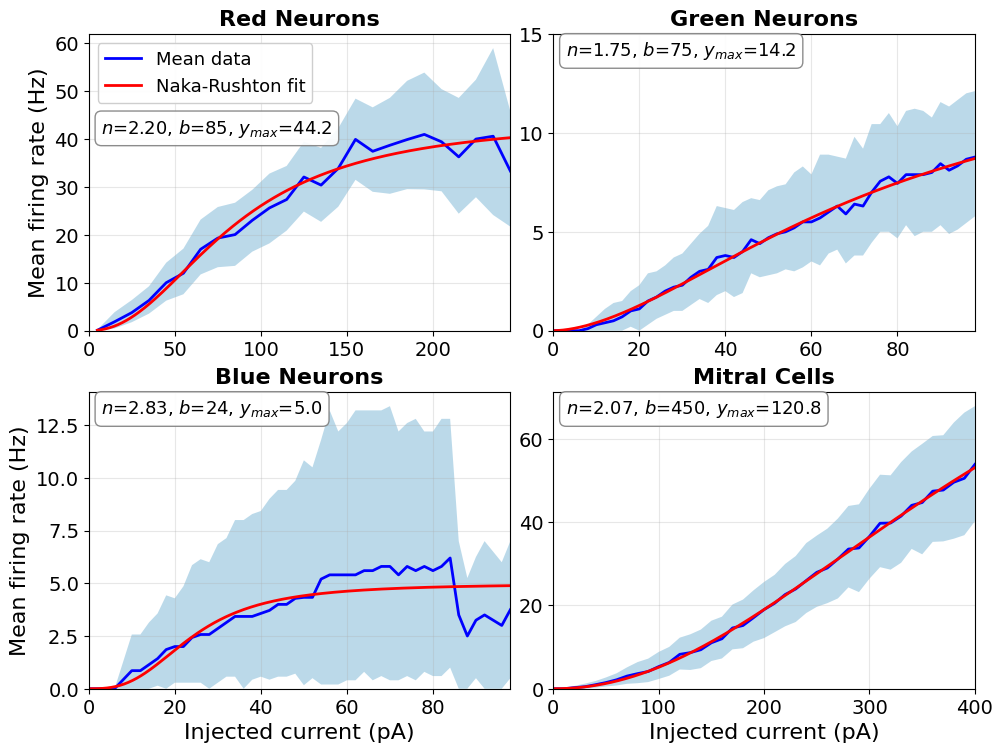

In [65]:
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG, FS_PARAM = 16, 16, 14, 13, 13
param_bbox = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.9)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), sharex=False)
dfs = [
    df_red_occluded.iloc[:-5],
    df_green_occluded,
    df_blue_occluded,
    df_mitral_occluded,
]
titles = ['Red Neurons', 'Green Neurons', 'Blue Neurons', 'Mitral Cells']

for i, (df_plot, title) in enumerate(zip(dfs, titles)):
    ax = axes.flat[i]
    x = np.asarray(df_plot.index, dtype=float)
    y = np.asarray(df_plot.mean(axis=1), dtype=float)
    fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100], maxfev=8000)

    print(f"\n{title}")
    print(f"n = {fit_params[0]:.3f}, b = {fit_params[1]:.3f}, y_max = {fit_params[2]:.3f}")

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = nr_full(x_fit, *fit_params)

    df_long = (
        df_plot.reset_index(names='current')
        .melt(id_vars='current', var_name='cell', value_name='firing_rate')
    )
    sns.lineplot(
        data=df_long, x='current', y='firing_rate', ax=ax,
        color='blue', linewidth=2, errorbar=('ci', 95), err_style='band',
        err_kws=dict(facecolor='#9ecae1', alpha=0.7, edgecolor='none'),
        label='Mean data' if i == 0 else None, legend=False,
    )
    ax.plot(
        x_fit, y_fit, color='red', linewidth=2,
        label='Naka-Rushton fit' if i == 0 else '_nolegend_',
    )
    ax.set_title(title, fontsize=FS_TITLE, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xlim(0, x.max())
    y_upper = max(ax.dataLim.ymax, y_fit.max()) * 1.05
    if i == 1:
        y_upper = np.ceil(y_upper / 5) * 5
        ax.set_yticks(np.arange(0, y_upper + 1, 5))
    ax.set_ylim(0, y_upper)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.grid(True, alpha=0.3)

    param_text = (
        f'$n$={fit_params[0]:.2f}, $b$={fit_params[1]:.0f}, '
        f'$y_{{max}}$={fit_params[2]:.1f}'
    )
    if i == 0:
        leg = ax.legend(loc='upper left', fontsize=FS_LEG, framealpha=0.95)
        fig.canvas.draw()
        param_y = leg.get_window_extent().transformed(ax.transAxes.inverted()).y0 - 0.02
    else:
        param_y = 0.98
    ax.text(
        0.03, param_y, param_text, transform=ax.transAxes,
        fontsize=FS_PARAM, va='top', ha='left', bbox=param_bbox,
    )

axes[0, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_ylabel('Mean firing rate (Hz)', fontsize=FS_LABEL)
axes[1, 0].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[1, 1].set_xlabel('Injected current (pA)', fontsize=FS_LABEL)
axes[0, 1].set_ylabel('')
axes[1, 1].set_ylabel('')
plt.tight_layout(pad=0.6)
plt.savefig('Figures_z/n_fit_all_cells_occluded.eps', bbox_inches='tight')
plt.show()